(114000, 21)
Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='object')
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Filas encontradas: 25
Canciones únicas: 24
                 track_name album_name
65427  CIRCUS (Korean Ver.)   MAXIDENT
65587                CIRCUS     CIRCUS
Canciones finales: 23


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

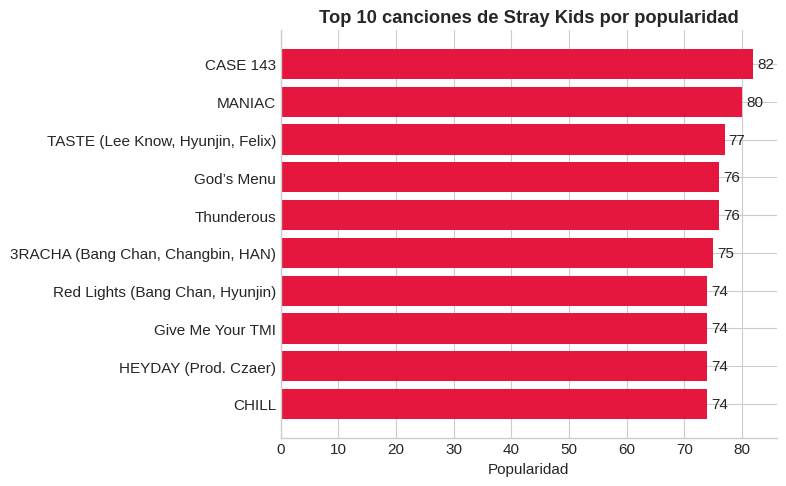

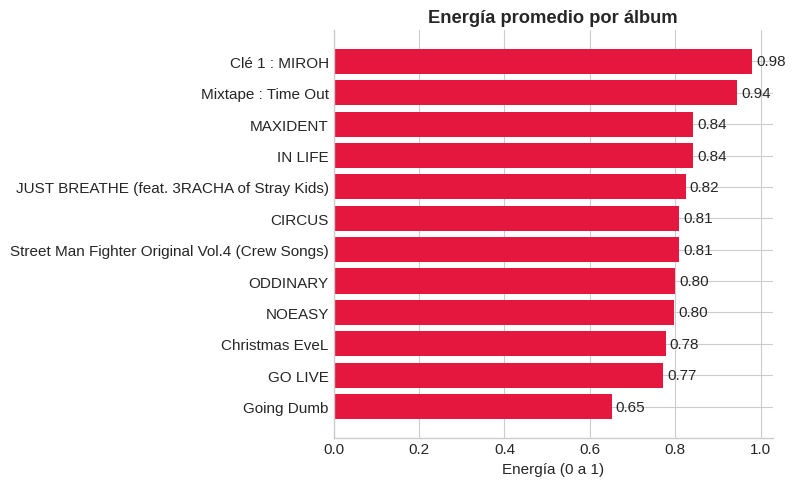

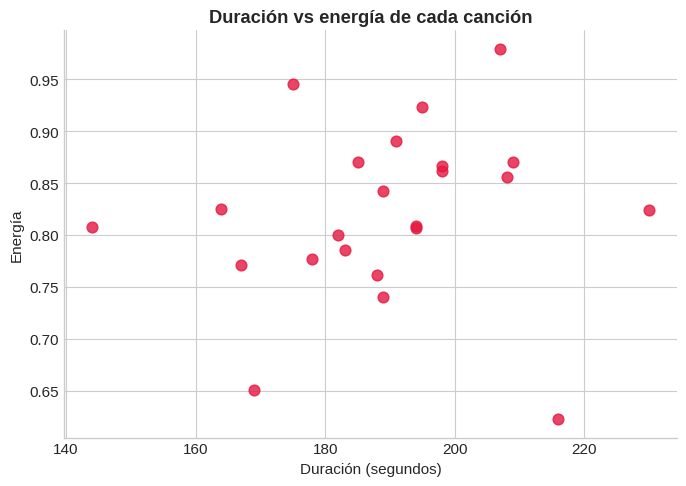

,mean,count
album_name,,
Clé 1 : MIROH,0.979000,1
Mixtape : Time Out,0.945000,1
IN LIFE,0.842000,1
MAXIDENT,0.842000,7
JUST BREATHE (feat. 3RACHA of Stray Kids),0.824000,1
CIRCUS,0.809000,1
Street Man Fighter Original Vol.4 (Crew Songs),0.808000,1
ODDINARY,0.798500,4
NOEASY,0.797333,3


Energía total (dinámica): 1611
Energía total (voraz):    1605
Tiempo usado: 3591 de 3600 segundos


,track_name,duracion,energy
0,God’s Menu,2:47,0.771
1,Christmas EveL,2:58,0.777
2,Thunderous,3:03,0.786
3,MANIAC,3:02,0.800
4,VENOM,3:14,0.807
5,HEYDAY (Prod. Czaer),2:24,0.808
6,CIRCUS,3:14,0.809
7,JUST BREATHE - feat. 3RACHA of Stray Kids,3:50,0.824
8,Lonely St.,2:44,0.825
9,Back Door,3:09,0.842


15 min -> dinámica: 447 | voraz: 447 | diferencia: 0
30 min -> dinámica: 864 | voraz: 864 | diferencia: 0
45 min -> dinámica: 1226 | voraz: 1194 | diferencia: 32
60 min -> dinámica: 1611 | voraz: 1605 | diferencia: 6


In [11]:
# 1. Cargar el CSV
import pandas as pd
from IPython.display import display

df = pd.read_csv("spotify-tracks.csv")
print(df.shape)
print(df.columns)
print(df.isna().sum())
display(df.head())

# 2. Filtrar para quedarnos solo con Stray Kids
skz = df[df["artists"].str.contains("Stray Kids", case=False, na=False)].copy()
print("Filas encontradas:", len(skz))

# 3. Quitar duplicados
skz = skz.drop_duplicates(subset="track_id")
skz = skz.drop_duplicates(subset="track_name")
print("Canciones únicas:", len(skz))

# 3b. Quitar la versión coreana de CIRCUS
print(skz[skz["track_name"].str.contains("CIRCUS", case=False)][["track_name", "album_name"]])
skz = skz[~skz["track_name"].str.contains("CIRCUS.*Korean", case=False, regex=True)]
print("Canciones finales:", len(skz))

# 4. Duración en segundos
skz["duracion_seg"] = skz["duration_ms"] // 1000

# 5. Guardar el CSV limpio
cols = ["track_name", "album_name", "duracion_seg", "energy", "popularity"]
skz[cols].to_csv("skz_limpio.csv", index=False)

from google.colab import files
files.download("skz_limpio.csv")

# Inicio de gráficas
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
COLOR = "#E5173F"

# 6. Las 10 canciones más populares
top = skz.sort_values("popularity", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(top["track_name"], top["popularity"], color=COLOR)
ax.bar_label(barras, padding=3)
ax.invert_yaxis()
ax.set_title("Top 10 canciones de Stray Kids por popularidad", fontweight="bold")
ax.set_xlabel("Popularidad")
plt.tight_layout()
plt.savefig("top10.png", dpi=200)
plt.show()

# 7. Energía promedio por álbum
por_album = skz.groupby("album_name")["energy"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(por_album.index, por_album.values, color=COLOR)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_title("Energía promedio por álbum", fontweight="bold")
ax.set_xlabel("Energía (0 a 1)")
plt.tight_layout()
plt.savefig("energia_album.png", dpi=200)
plt.show()

# 8. Duración vs energía (esto es justo peso vs valor de la mochila)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(skz["duracion_seg"], skz["energy"], color=COLOR, s=60, alpha=0.8)
ax.set_title("Duración vs energía de cada canción", fontweight="bold")
ax.set_xlabel("Duración (segundos)")
ax.set_ylabel("Energía")
plt.tight_layout()
plt.savefig("duracion_vs_energia.png", dpi=200)
plt.show()

# Energía por álbum y cuántas canciones tiene cada uno
display(skz.groupby("album_name")["energy"].agg(["mean", "count"]).sort_values("mean", ascending=False))

# 9. Mochila con programación dinámica
canciones = skz.reset_index(drop=True)
pesos = canciones["duracion_seg"].tolist()
valores = (canciones["energy"] * 100).round().astype(int).tolist()

def mochila_dp(pesos, valores, W):
    n = len(pesos)
    dp = [[0] * (W + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        for w in range(W + 1):
            dp[i][w] = dp[i - 1][w]                      # no tomar la canción
            if pesos[i - 1] <= w:                        # tomarla si cabe
                dp[i][w] = max(dp[i][w], dp[i - 1][w - pesos[i - 1]] + valores[i - 1])
    # reconstruir qué canciones se eligieron
    elegidas, w = [], W
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            elegidas.append(i - 1)
            w -= pesos[i - 1]
    return dp[n][W], elegidas[::-1]

def mochila_voraz(pesos, valores, W):
    orden = sorted(range(len(pesos)), key=lambda i: valores[i] / pesos[i], reverse=True)
    total, usado, elegidas = 0, 0, []
    for i in orden:
        if usado + pesos[i] <= W:
            usado += pesos[i]
            total += valores[i]
            elegidas.append(i)
    return total, elegidas

# Prueba con un concierto de 1 hora
W = 60 * 60
mejor_dp, sel_dp = mochila_dp(pesos, valores, W)
mejor_gr, sel_gr = mochila_voraz(pesos, valores, W)

print("Energía total (dinámica):", mejor_dp)
print("Energía total (voraz):   ", mejor_gr)
print("Tiempo usado:", sum(pesos[i] for i in sel_dp), "de", W, "segundos")

# Setlist ordenado de menos a más energía
setlist = canciones.loc[sel_dp, ["track_name", "duracion_seg", "energy"]].sort_values("energy")
setlist["duracion"] = setlist["duracion_seg"].apply(lambda s: f"{s // 60}:{s % 60:02d}")
display(setlist[["track_name", "duracion", "energy"]].reset_index(drop=True))

# Comparar dinámica vs voraz con distintas duraciones de concierto
for minutos in [15, 30, 45, 60]:
    W = minutos * 60
    total_dp, _ = mochila_dp(pesos, valores, W)
    total_gr, _ = mochila_voraz(pesos, valores, W)
    print(f"{minutos} min -> dinámica: {total_dp} | voraz: {total_gr} | diferencia: {total_dp - total_gr}")